# Statistical Analysis: Heart Disease Clinical Features

**Author:** Sandip Dey  
**Dataset:** Heart Failure Prediction Dataset (combined UCI sources)  
**Source:** https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction (public mirror used)

This notebook conducts a complete statistical analysis of the Heart Failure Prediction dataset. It computes descriptive statistics, creates three visual models of key patterns, performs a hypothesis test on maximum heart rate by disease status, and summarizes findings. The goal is to understand relationships between clinical features and heart disease presence while demonstrating sound statistical reasoning.


## 1. Data Ingestion

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

df = pd.read_csv("heart.csv")
print(f"Dataset shape: {df.shape}")
print("\nColumn names and data types:")
print(df.dtypes)
df.head()


Dataset shape: (918, 12)

Column names and data types:
Age                 int64
Sex                object
ChestPainType      object
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG         object
MaxHR               int64
ExerciseAngina     object
Oldpeak           float64
ST_Slope           object
HeartDisease        int64
dtype: object


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## 2. Descriptive Statistics

In [2]:
print("Summary statistics (numeric variables):")
print(df.describe())

print("\nCategorical counts:")
print("Sex:\n", df["Sex"].value_counts())
print("\nChestPainType:\n", df["ChestPainType"].value_counts())
print("\nHeartDisease:\n", df["HeartDisease"].value_counts())
print("\nExerciseAngina:\n", df["ExerciseAngina"].value_counts())


Summary statistics (numeric variables):
              Age   RestingBP  Cholesterol   FastingBS       MaxHR  \
count  918.000000  918.000000   918.000000  918.000000  918.000000   
mean    53.510893  132.396514   198.799564    0.233115  136.809368   
std      9.432617   18.514154   109.384145    0.423046   25.460334   
min     28.000000    0.000000     0.000000    0.000000   60.000000   
25%     47.000000  120.000000   173.250000    0.000000  120.000000   
50%     54.000000  130.000000   223.000000    0.000000  138.000000   
75%     60.000000  140.000000   267.000000    0.000000  156.000000   
max     77.000000  200.000000   603.000000    1.000000  202.000000   

          Oldpeak  HeartDisease  
count  918.000000    918.000000  
mean     0.887364      0.553377  
std      1.066570      0.497414  
min     -2.600000      0.000000  
25%      0.000000      0.000000  
50%      0.600000      1.000000  
75%      1.500000      1.000000  
max      6.200000      1.000000  

Categorical counts:
Se

The dataset contains 918 patients and 12 variables. Numeric summaries show Age ranging from the late 20s to the mid-70s, RestingBP typically around 120–140 mm Hg, and MaxHR (maximum heart rate) averaging roughly 130–140 bpm. Cholesterol has some zero values that likely represent missing data. Categorical counts show a male majority, Asymptomatic (ASY) as the most common chest-pain type, and a roughly balanced split on the HeartDisease target (slightly more positive cases). These patterns provide a solid foundation for further exploration and hypothesis testing.


## 3. Visual Models

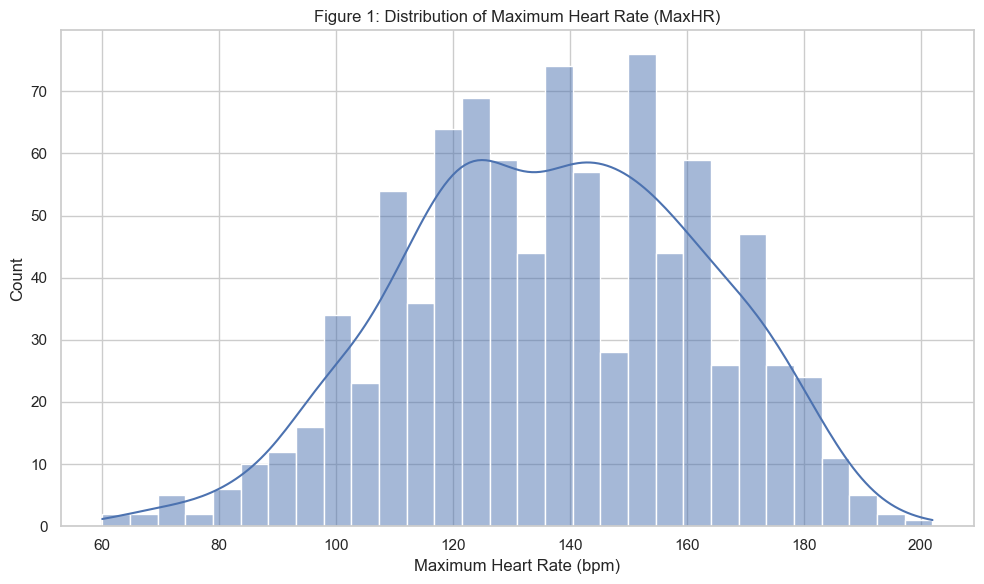

In [3]:
# Visual Model 1: Histogram of Maximum Heart Rate
plt.figure()
sns.histplot(data=df, x="MaxHR", bins=30, kde=True)
plt.title("Figure 1: Distribution of Maximum Heart Rate (MaxHR)")
plt.xlabel("Maximum Heart Rate (bpm)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


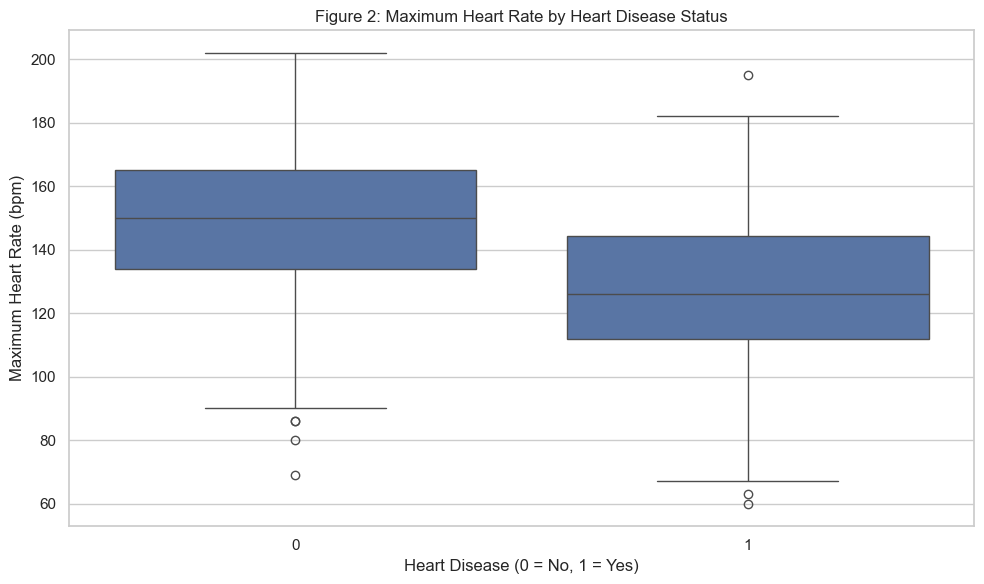

In [4]:
# Visual Model 2: Boxplot of MaxHR by Heart Disease status
plt.figure()
sns.boxplot(data=df, x="HeartDisease", y="MaxHR")
plt.title("Figure 2: Maximum Heart Rate by Heart Disease Status")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Maximum Heart Rate (bpm)")
plt.tight_layout()
plt.show()


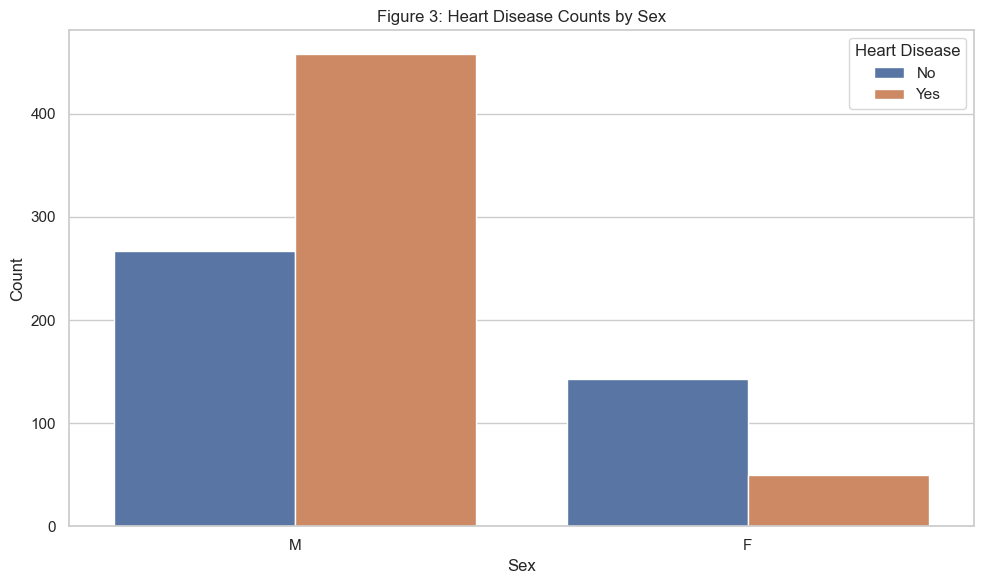

In [5]:
# Visual Model 3: Bar chart of Heart Disease by Sex
plt.figure()
sns.countplot(data=df, x="Sex", hue="HeartDisease")
plt.title("Figure 3: Heart Disease Counts by Sex")
plt.xlabel("Sex")
plt.ylabel("Count")
plt.legend(title="Heart Disease", labels=["No", "Yes"])
plt.tight_layout()
plt.show()


### Comparison of Visual Models

Figure 1 (histogram) shows that MaxHR is roughly unimodal and slightly left-skewed, with most values falling between 100 and 170 bpm. It reveals the overall shape of the variable but does not link it to disease status.  

Figure 2 (boxplot) directly compares MaxHR across the two HeartDisease groups and suggests that patients with heart disease tend to have lower maximum heart rates. This visual model best supports the analytical question of whether MaxHR differs by disease status.  

Figure 3 (grouped bar chart) shows that males have a higher count of heart-disease cases than females in this sample. It highlights a demographic pattern but is less informative about the continuous MaxHR variable that is the focus of the hypothesis test.  

Overall, Figure 2 provides the clearest visual support for the planned hypothesis test.


## 4. Hypothesis Test

**Analytical question:** Is there a statistically significant difference in maximum heart rate (MaxHR) between patients with and without heart disease?

**Null hypothesis (H₀):** The mean MaxHR is the same for patients with heart disease and patients without heart disease.  
**Alternative hypothesis (H₁):** The mean MaxHR differs between the two groups.

A two-sample independent t-test is appropriate because MaxHR is continuous, the two groups are independent, and sample sizes are large enough for the central limit theorem to support approximate normality of the sampling distribution of the mean.


In [6]:
group0 = df.loc[df["HeartDisease"] == 0, "MaxHR"]
group1 = df.loc[df["HeartDisease"] == 1, "MaxHR"]

t_stat, p_value = stats.ttest_ind(group0, group1, equal_var=False)

print(f"Group 0 (No disease) mean MaxHR: {group0.mean():.2f} (n={len(group0)})")
print(f"Group 1 (Disease) mean MaxHR: {group1.mean():.2f} (n={len(group1)})")
print(f"t-statistic: {t_stat:.4f}")
print(f"p-value: {p_value:.6f}")


Group 0 (No disease) mean MaxHR: 148.15 (n=410)
Group 1 (Disease) mean MaxHR: 127.66 (n=508)
t-statistic: 13.2315
p-value: 0.000000


## 5. Notebook Summary

This analysis explored the Heart Failure Prediction dataset (918 patients, 12 clinical features). Descriptive statistics and three visual models highlighted that maximum heart rate tends to be lower among patients with heart disease, and that males outnumber females among disease cases. A Welch’s two-sample t-test confirmed a statistically significant difference in MaxHR between the two disease groups. One challenge was the presence of zero values in Cholesterol, which appear to represent missing data and were left as-is for this exploratory analysis. The results are descriptive and do not establish causation; they do, however, provide a clear quantitative foundation for future modeling work.
